In [ ]:
import requests, io, time
import matplotlib.pyplot as plt
from PIL import Image
from my_secrets import CF_ID, CF_API
CF_ACCOUNT_ID = CF_ID
CF_TOKEN = CF_API

MODEL_ID = "@cf/stabilityai/stable-diffusion-xl-base-1.0"
API_URL = f"https://api.cloudflare.com/client/v4/accounts/{CF_ACCOUNT_ID}/ai/run/{MODEL_ID}"
headers = {"Authorization": f"Bearer {CF_TOKEN}"}
print("Configuración lista.")

Configuración lista.


In [2]:
def generar_imagen(prompt, cfg=7.5, pasos=20, seed=42):
    payload = {"prompt": prompt, "guidance": cfg, "num_steps": pasos, "seed": seed}
    response = requests.post(API_URL, headers=headers, json=payload)
    if response.status_code != 200:
        print(f"Error {response.status_code}: {response.text}")
        return None
    return Image.open(io.BytesIO(response.content)).convert("RGB")

Generando imagen... (puede tardar 15–30 segundos)


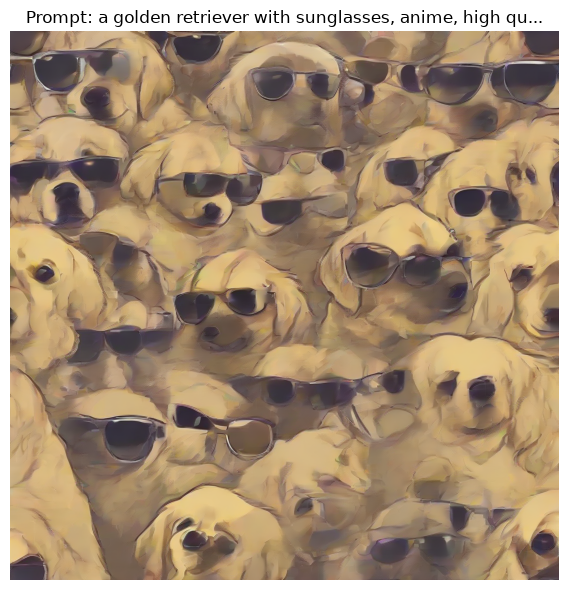

Imagen guardada como imagen_01.png


In [4]:
import matplotlib.pyplot as plt

mi_prompt = "a golden retriever with sunglasses, anime, high quality"

print("Generando imagen... (puede tardar 15–30 segundos)")
imagen = generar_imagen(prompt=mi_prompt, pasos=4)

if imagen is not None:
    plt.figure(figsize=(6, 6))
    plt.imshow(imagen)
    plt.axis("off")
    plt.title(f"Prompt: {mi_prompt[:50]}...")
    plt.tight_layout()
    plt.show()

    imagen.save("imagen_01.png")
    print("Imagen guardada como imagen_01.png")
else:
    print("No se generó la imagen. Mira el mensaje de error de arriba.")

Generando con CFG=1...
Generando con CFG=4...
Generando con CFG=7...
Generando con CFG=10...
Generando con CFG=15...


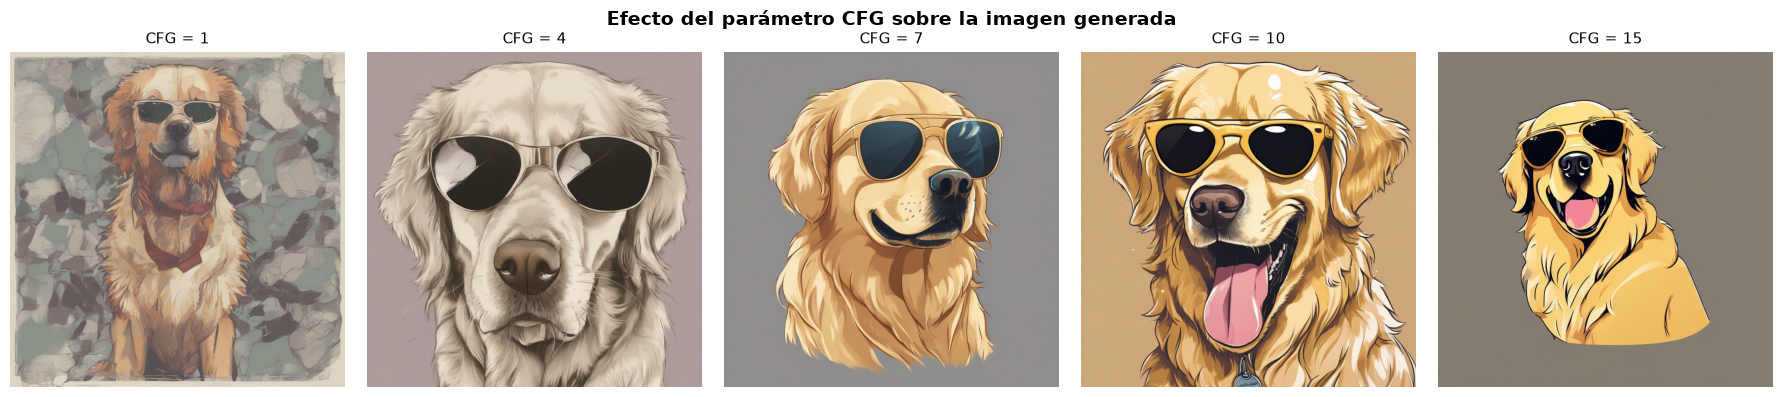

Gráfica guardada cómo experimento_cfg.png


In [5]:
# Valores de CFG qué vamos a comparar
valores_cfg = [1, 4, 7, 10, 15]
# Usamos el mismo prompt y seed para qué la comparación sea justa
prompt_experimento = "a golden retriever with sunglasses, anime, high quality"
seed_fijo = 42 # La misma semilla garantiza qué la diferencia es SOLO por CFG
imagenes_cfg = [] # Lista donde guardaremos los resultados
for cfg in valores_cfg:
    print(f"Generando con CFG={cfg}...")
    img = generar_imagen(prompt=prompt_experimento,cfg=cfg,pasos=20,seed=seed_fijo)
    if img:
        imagenes_cfg.append((cfg, img))
        time.sleep(2) # Pausa para no saturar la API
# Mostramos todas las imágenes en una fila comparativa
fig, axes = plt.subplots(1, len(imagenes_cfg), figsize=(18, 4))
fig.suptitle("Efecto del parámetro CFG sobre la imagen generada",fontsize=14, fontweight="bold")
for ax, (cfg, img) in zip(axes, imagenes_cfg):
    ax.imshow(img)
    ax.set_title(f"CFG = {cfg}", fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.savefig("experimento_cfg.png", dpi=150, bbox_inches="tight")
plt.show()
print("Gráfica guardada cómo experimento_cfg.png")

In [6]:
from sentence_transformers import SentenceTransformer, util
import torch
import numpy as np
# Cargamos el modelo CLIP (se descarga automáticamente ~400 MB la primera vez)
print("Cargando modelo CLIP... (primera vez puede tardar 2-3 minutos)")
clip_model = SentenceTransformer("clip-ViT-B-32")
print("Modelo CLIP cargado.")
def calcular_clip_score(imagen_pil, texto):
    """Calcula la similitud entre una imagen y un texto (0-100)."""
    # Codificamos la imagen y el texto en el mismo espacio vectorial
    emb_imagen = clip_model.encode(imagen_pil, convert_to_tensor=True)
    emb_texto = clip_model.encode(texto, convert_to_tensor=True)
    # Calculamos la similitud coseno (0 = nada parecido, 1 = identico)
    similitud = util.cos_sim(emb_imagen, emb_texto).item()
    # Convertimos a escala 0-100 para qué sea mas legible
    return round(similitud * 100, 2)
# Calculamos el CLIP Score para cada imagen del experimento CFG
scores = []
for cfg, img in imagenes_cfg:
    score = calcular_clip_score(img, prompt_experimento)
    scores.append((cfg, score))
    print(f"CFG={cfg:3d} -> CLIP Score = {score}")

Cargando modelo CLIP... (primera vez puede tardar 2-3 minutos)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Modelo CLIP cargado.
CFG=  1 -> CLIP Score = 28.51
CFG=  4 -> CLIP Score = 35.75
CFG=  7 -> CLIP Score = 38.1
CFG= 10 -> CLIP Score = 37.72
CFG= 15 -> CLIP Score = 37.01


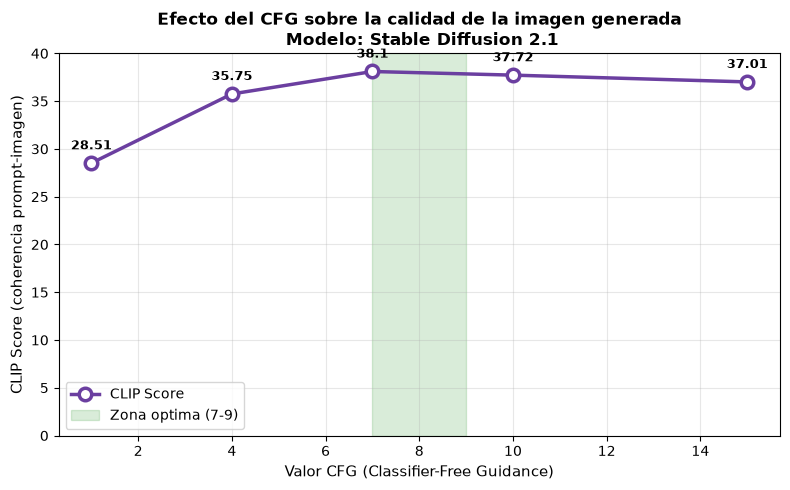

Gráfica guardada cómo grafica_cfg_vs_clip.png


In [7]:
# Separamos los valores para graficar
cfgs_list = [x[0] for x in scores]
scores_list = [x[1] for x in scores]
# Creamos la grafica
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(cfgs_list, scores_list, marker="o", color="#6B3FA0",
linewidth=2.5, markersize=9, markerfacecolor="white",
markeredgewidth=2.5, label="CLIP Score")
# Marcamos la zona optima (CFG 7-9) con un rectangulo verde
ax.axvspan(7, 9, alpha=0.15, color="green", label="Zona optima (7-9)")
# Etiquetamos cada punto con su valor
for cfg, score in scores:
    ax.annotate(f"{score}", (cfg, score),
                textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=9, fontweight="bold")
ax.set_xlabel("Valor CFG (Classifier-Free Guidance)", fontsize=11)
ax.set_ylabel("CLIP Score (coherencia prompt-imagen)", fontsize=11)
ax.set_title("Efecto del CFG sobre la calidad de la imagen generada\n Modelo: Stable Diffusion 2.1", fontsize=12, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 40)
plt.tight_layout()
plt.savefig("gráfica_cfg_vs_clip.png", dpi=150, bbox_inches="tight")
plt.show()
print("Gráfica guardada cómo grafica_cfg_vs_clip.png")